In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import correlate2d, convolve2d

np.random.seed(42)

EPSILON = 1e-15

In [3]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(x, 0)

def lrelu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)

def linear(x):
    return x

def sigmoid_derivative(output):
    return output * (1.0 - output)

def tanh_derivative(output):
    return 1.0 - output ** 2

def relu_derivative(output):
    return (output > 0).astype(float)

def lrelu_derivative(output, alpha=0.1):
    return np.where(output > 0, 1.0, alpha)

def linear_derivative(output):
    return np.ones_like(output)

ACTIVATIONS = {
    'sigmoid': (sigmoid, sigmoid_derivative),
    'relu':    (relu, relu_derivative),
    'tanh':    (tanh, tanh_derivative),
    'lrelu':   (lrelu, lrelu_derivative),
    'linear':  (linear, linear_derivative),
}

def softmax(x):
    shifted = x - np.max(x)
    exps = np.exp(shifted)
    return exps / np.sum(exps)

def cross_entropy(probs, target):
    return -np.sum(target * np.log(np.maximum(probs, EPSILON)))

In [4]:
class Conv2D:
    def __init__(self, num_filters, kernel_size, num_input_channels, activation="lrelu"):
        self.num_filters = num_filters
        self.k = kernel_size
        self.c_in = num_input_channels
        self.pad = (kernel_size - 1) // 2

        # He/Xavier-ish init scaled by fan-in/fan-out over the kernel volume
        fan_in = num_input_channels * kernel_size * kernel_size
        fan_out = num_filters * kernel_size * kernel_size
        limit = np.sqrt(6 / (fan_in + fan_out))
        self.weights = np.random.uniform(
            -limit, limit, (num_filters, num_input_channels, kernel_size, kernel_size)
        )
        self.bias = np.zeros(num_filters)
        self.activation, self.derivative = ACTIVATIONS[activation]

        self.input = None            # padded input, cached for backward
        self.input_shape = None      # unpadded (H, W)
        self.output = None

    def forward(self, x):
        # x: (c_in, H, W)
        c_in, H, W = x.shape
        self.input_shape = (H, W)

        if self.pad > 0:
            x_padded = np.pad(x, ((0, 0), (self.pad, self.pad), (self.pad, self.pad)), mode="constant")
        else:
            x_padded = x
        self.input = x_padded

        pre_activation = np.zeros((self.num_filters, H, W))
        for f in range(self.num_filters):
            acc = np.zeros((H, W))
            for c in range(c_in):
                acc += correlate2d(x_padded[c], self.weights[f, c], mode="valid")
            pre_activation[f] = acc + self.bias[f]

        self.output = self.activation(pre_activation)
        return self.output

    def backward(self, d_output):
        # d_output: dL/d(self.output) -- same shape as self.output, (num_filters, H, W)
        d_pre = d_output * self.derivative(self.output)

        H, W = self.input_shape
        self.d_weights = np.zeros_like(self.weights)
        self.d_bias = np.zeros(self.num_filters)
        d_input_padded = np.zeros_like(self.input)

        for f in range(self.num_filters):
            self.d_bias[f] = np.sum(d_pre[f])
            for c in range(self.c_in):
                self.d_weights[f, c] = correlate2d(self.input[c], d_pre[f], mode="valid")
                d_input_padded[c] += convolve2d(d_pre[f], self.weights[f, c], mode="full")

        if self.pad > 0:
            d_input = d_input_padded[:, self.pad:-self.pad, self.pad:-self.pad]
        else:
            d_input = d_input_padded
        return d_input

    def update(self, learning_rate):
        self.weights -= learning_rate * self.d_weights
        self.bias -= learning_rate * self.d_bias

In [5]:
class MaxPool2D:
    def __init__(self, size=2, stride=2):
        assert size == stride, "this implementation only supports non-overlapping pooling"
        self.size = size

    def forward(self, x):
        c, H, W = x.shape
        s = self.size
        assert H % s == 0 and W % s == 0, "input size must be divisible by pool size"

        x_reshaped = x.reshape(c, H // s, s, W // s, s)
        out = x_reshaped.max(axis=(2, 4))

        out_upsampled = np.repeat(np.repeat(out, s, axis=1), s, axis=2)
        mask = (x == out_upsampled).astype(float)

        # normalize so ties split the gradient instead of duplicating it
        counts = mask.reshape(c, H // s, s, W // s, s).sum(axis=(2, 4))
        counts_upsampled = np.repeat(np.repeat(counts, s, axis=1), s, axis=2)
        self.mask = mask / counts_upsampled
        self.input_shape = x.shape

        self.output = out
        return out

    def backward(self, d_output):
        s = self.size
        d_upsampled = np.repeat(np.repeat(d_output, s, axis=1), s, axis=2)
        return self.mask * d_upsampled


class Flatten:
    def forward(self, x):
        self.input_shape = x.shape
        self.output = x.flatten()
        return self.output

    def backward(self, d_output):
        return d_output.reshape(self.input_shape)

In [6]:
class Layer:
    def __init__(self, num_neurons, num_inputs, activation="lrelu"):
        limit = np.sqrt(6 / (num_inputs + num_neurons))
        self.weights = np.random.uniform(-limit, limit, (num_neurons, num_inputs))
        self.bias = np.zeros(num_neurons)
        self.activation, self.derivative = ACTIVATIONS[activation]

        self.inputs = None
        self.output = None
        self.error = None

    def forward(self, inputs):
        self.inputs = inputs
        total = self.weights @ inputs + self.bias
        self.output = self.activation(total)
        return self.output

In [7]:
class CNN:
    def __init__(self, num_classes=10, num_filters=8, kernel_size=3, hidden_size=64):
        self.conv1 = Conv2D(num_filters=num_filters, kernel_size=kernel_size,
                             num_input_channels=1, activation="lrelu")
        self.pool1 = MaxPool2D(size=2, stride=2)
        self.flatten = Flatten()

        flat_size = num_filters * 14 * 14  # 28x28 -> pool 2x2 -> 14x14, per filter
        self.dense_hidden = Layer(hidden_size, flat_size, activation="lrelu")
        self.dense_output = Layer(num_classes, hidden_size, activation="linear")

    def forward(self, image_flat):
        # image_flat: 784-length vector, values in [0, 1]
        x = np.asarray(image_flat, dtype=float).reshape(1, 28, 28)
        x = self.conv1.forward(x)
        x = self.pool1.forward(x)
        x = self.flatten.forward(x)
        x = self.dense_hidden.forward(x)
        logits = self.dense_output.forward(x)
        self.probs = softmax(logits)
        return self.probs

    def backward(self, target):
        target = np.asarray(target, dtype=float)

        # combined softmax + cross-entropy gradient
        d_logits = self.probs - target
        self.dense_output.error = d_logits

        d_hidden_out = self.dense_output.weights.T @ d_logits
        d_hidden_pre = d_hidden_out * self.dense_hidden.derivative(self.dense_hidden.output)
        self.dense_hidden.error = d_hidden_pre

        d_flat = self.dense_hidden.weights.T @ d_hidden_pre
        d_pool_out = self.flatten.backward(d_flat)
        d_conv_out = self.pool1.backward(d_pool_out)
        self.conv1.backward(d_conv_out)  # stores conv1.d_weights / conv1.d_bias

    def update_weights(self, learning_rate=0.05):
        self.dense_output.weights -= learning_rate * np.outer(self.dense_output.error, self.dense_output.inputs)
        self.dense_output.bias -= learning_rate * self.dense_output.error

        self.dense_hidden.weights -= learning_rate * np.outer(self.dense_hidden.error, self.dense_hidden.inputs)
        self.dense_hidden.bias -= learning_rate * self.dense_hidden.error

        self.conv1.update(learning_rate)

In [8]:
def dataloader(filepath):
    df = pd.read_csv(filepath)
    labels = df.iloc[:, 0].values
    values = df.iloc[:, 1:].values / 255.0
    return values, labels

def one_hot(label, num_classes=10):
    target = np.zeros(num_classes)
    target[int(label)] = 1.0
    return target

def evaluate(model, images, labels):
    correct = 0
    total_loss = 0.0
    for image, label in zip(images, labels):
        probs = model.forward(image)
        target = one_hot(label)
        total_loss += cross_entropy(probs, target)
        if np.argmax(probs) == int(label):
            correct += 1
    acc = correct / len(images) * 100
    avg_loss = total_loss / len(images)
    return avg_loss, acc

In [ ]:
epochs = 5
learning_rate = 0.05
sample_size = 25000  
test_size = 200

all_train_x, all_train_y = dataloader("data/mnist/mnist_train.csv")
test_x, test_y = dataloader("data/mnist/mnist_test.csv")

pool_train_x, pool_train_y = all_train_x[test_size:], all_train_y[test_size:]
val_x, val_y = all_train_x[:test_size], all_train_y[:test_size]

model = CNN(num_classes=10, num_filters=8, kernel_size=3, hidden_size=64)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epochs):
    indices = np.random.choice(len(pool_train_x), size=sample_size, replace=False)
    epoch_x = pool_train_x[indices]
    epoch_y = pool_train_y[indices]

    total_loss = 0.0
    correct = 0
    for i, (image, label) in enumerate(zip(epoch_x, epoch_y)):
        probs = model.forward(image)
        target = one_hot(label)

        total_loss += cross_entropy(probs, target)
        if np.argmax(probs) == int(label):
            correct += 1

        model.backward(target)
        model.update_weights(learning_rate)

        if (i + 1) % 1000 == 0:
            print(f"Epoch {epoch + 1} | Sample {i + 1}/{sample_size} | Interm Acc: {correct / (i + 1) * 100:.1f}%")

    train_loss = total_loss / sample_size
    train_acc = correct / sample_size * 100
    val_loss, val_acc = evaluate(model, val_x, val_y)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"=== Epoch {epoch + 1} Summary ===")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%\n")

test_loss, test_acc = evaluate(model, test_x, test_y)
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")

Epoch 1 | Sample 1000/5000 | Interm Acc: 72.3%
Epoch 1 | Sample 2000/5000 | Interm Acc: 78.3%
Epoch 1 | Sample 3000/5000 | Interm Acc: 81.4%
Epoch 1 | Sample 4000/5000 | Interm Acc: 84.0%
Epoch 1 | Sample 5000/5000 | Interm Acc: 85.1%
=== Epoch 1 Summary ===
Train Loss: 0.4954 | Train Acc: 85.10%
Val Loss:   0.3823 | Val Acc:   90.00%

Epoch 2 | Sample 1000/5000 | Interm Acc: 90.2%
Epoch 2 | Sample 2000/5000 | Interm Acc: 89.7%
Epoch 2 | Sample 3000/5000 | Interm Acc: 90.8%
Epoch 2 | Sample 4000/5000 | Interm Acc: 91.1%
Epoch 2 | Sample 5000/5000 | Interm Acc: 91.2%
=== Epoch 2 Summary ===
Train Loss: 0.2941 | Train Acc: 91.18%
Val Loss:   0.2892 | Val Acc:   90.50%

Epoch 3 | Sample 1000/5000 | Interm Acc: 92.1%
Epoch 3 | Sample 2000/5000 | Interm Acc: 92.9%
Epoch 3 | Sample 3000/5000 | Interm Acc: 92.9%
Epoch 3 | Sample 4000/5000 | Interm Acc: 92.9%
Epoch 3 | Sample 5000/5000 | Interm Acc: 93.2%
=== Epoch 3 Summary ===
Train Loss: 0.2448 | Train Acc: 93.20%
Val Loss:   0.4659 | Val A

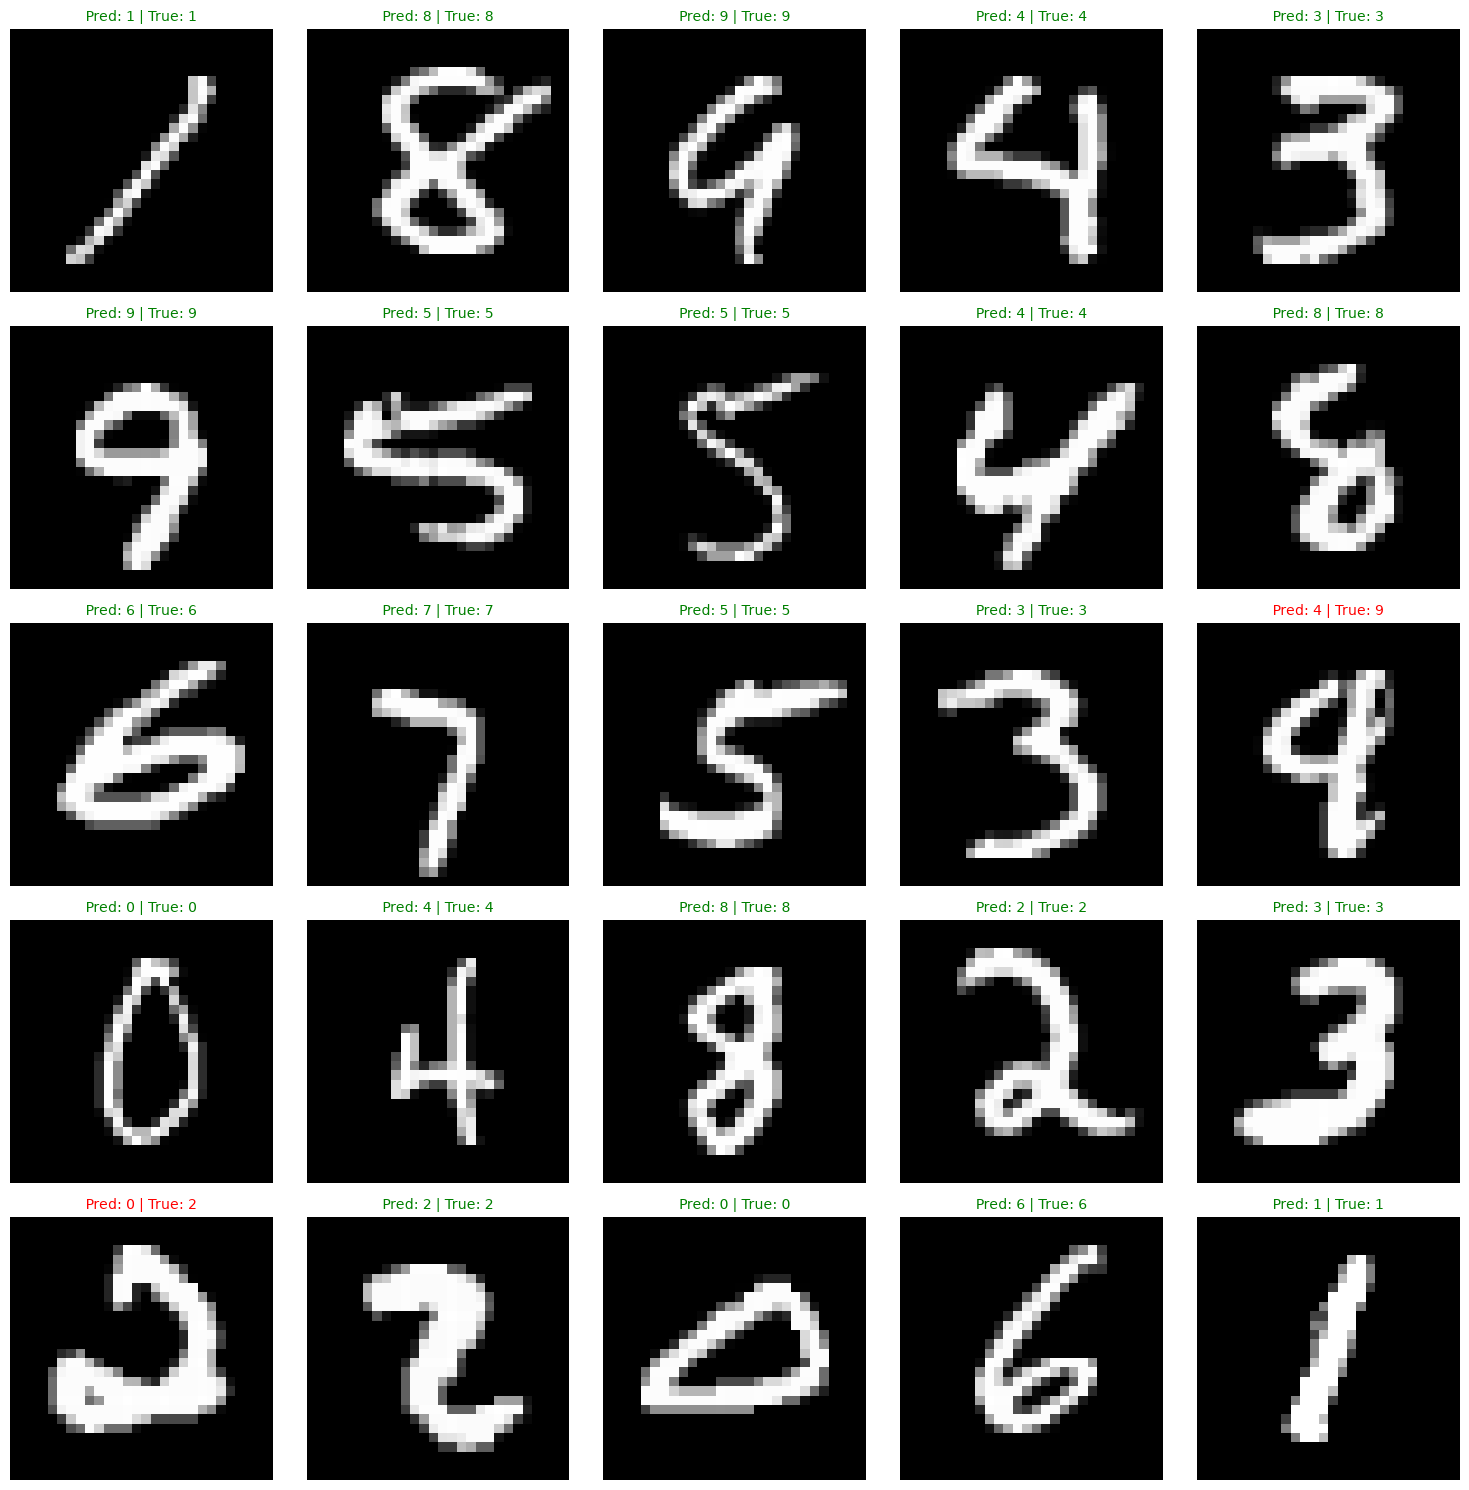

In [11]:
def plot_prediction_samples(model, test_x, test_y, num_samples=25, cols=5, randomize=True):
    rows = math.ceil(num_samples / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    indices = (np.random.choice(len(test_x), size=num_samples, replace=False)
               if randomize else np.arange(num_samples))

    for i, idx in enumerate(indices):
        image, true_label = test_x[idx], int(test_y[idx])
        probs = model.forward(image)
        pred_label = int(np.argmax(probs))

        axes[i].imshow(image.reshape(28, 28), cmap="gray")
        color = "green" if pred_label == true_label else "red"
        axes[i].set_title(f"Pred: {pred_label} | True: {true_label}", color=color, fontsize=10)
        axes[i].axis("off")

    for j in range(num_samples, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

plot_prediction_samples(model, test_x, test_y, num_samples=25, cols=5)

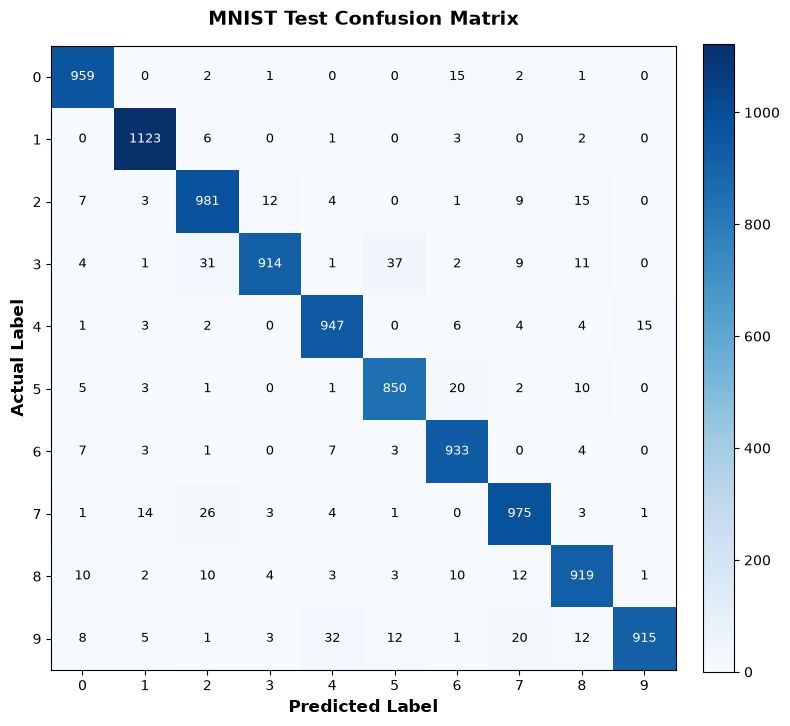

Total Test Samples: 10000
Overall Accuracy:   95.16%
Total Errors:       484
---------------------------------------------
Top 5 Most Frequent Misclassifications:
---------------------------------------------
 1. Actual [3] predicted as [5] -> 37 times (7.6% of all errors)
 2. Actual [9] predicted as [4] -> 32 times (6.6% of all errors)
 3. Actual [3] predicted as [2] -> 31 times (6.4% of all errors)
 4. Actual [7] predicted as [2] -> 26 times (5.4% of all errors)
 5. Actual [5] predicted as [6] -> 20 times (4.1% of all errors)


In [12]:
def evaluate_and_analyze_errors(model, test_x, test_y, num_classes=10, top_k=5):
    cm = np.zeros((num_classes, num_classes), dtype=int)

    error_counts = {}
    error_indices = []
    for idx, (image, label) in enumerate(zip(test_x, test_y)):
        actual = int(label)
        probs = model.forward(image)
        pred = int(np.argmax(probs))

        cm[actual, pred] += 1

        if actual != pred:
            pair = (actual, pred)
            error_counts[pair] = error_counts.get(pair, 0) + 1
            error_indices.append((idx, actual, pred))

    fig, ax = plt.subplots(figsize=(8, 8))
    im = ax.imshow(cm, cmap="Blues")

    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))
    ax.set_xticklabels([str(i) for i in range(num_classes)])
    ax.set_yticklabels([str(i) for i in range(num_classes)])

    ax.set_xlabel("Predicted Label", fontsize=12, fontweight="bold")
    ax.set_ylabel("Actual Label", fontsize=12, fontweight="bold")
    ax.set_title("MNIST Test Confusion Matrix", fontsize=14, fontweight="bold", pad=15)

    thresh = cm.max() / 2.0
    for i in range(num_classes):
        for j in range(num_classes):
            val = cm[i, j]
            color = "white" if val > thresh else "black"
            ax.text(j, i, f"{val}", ha="center", va="center", color=color, fontsize=9)

    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    sorted_errors = sorted(error_counts.items(), key=lambda item: item[1], reverse=True)
    total_errors = sum(error_counts.values())
    total_samples = len(test_x)
    accuracy = ((total_samples - total_errors) / total_samples) * 100

    print(f"Total Test Samples: {total_samples}")
    print(f"Overall Accuracy:   {accuracy:.2f}%")
    print(f"Total Errors:       {total_errors}")
    print("-" * 45)
    print(f"Top {min(top_k, len(sorted_errors))} Most Frequent Misclassifications:")
    print("-" * 45)

    for rank, ((actual, pred), count) in enumerate(sorted_errors[:top_k], start=1):
        percentage_of_errors = (count / total_errors) * 100 if total_errors > 0 else 0
        print(f" {rank}. Actual [{actual}] predicted as [{pred}] -> {count} times ({percentage_of_errors:.1f}% of all errors)")

    return error_indices

error_indices = evaluate_and_analyze_errors(model, test_x, test_y)

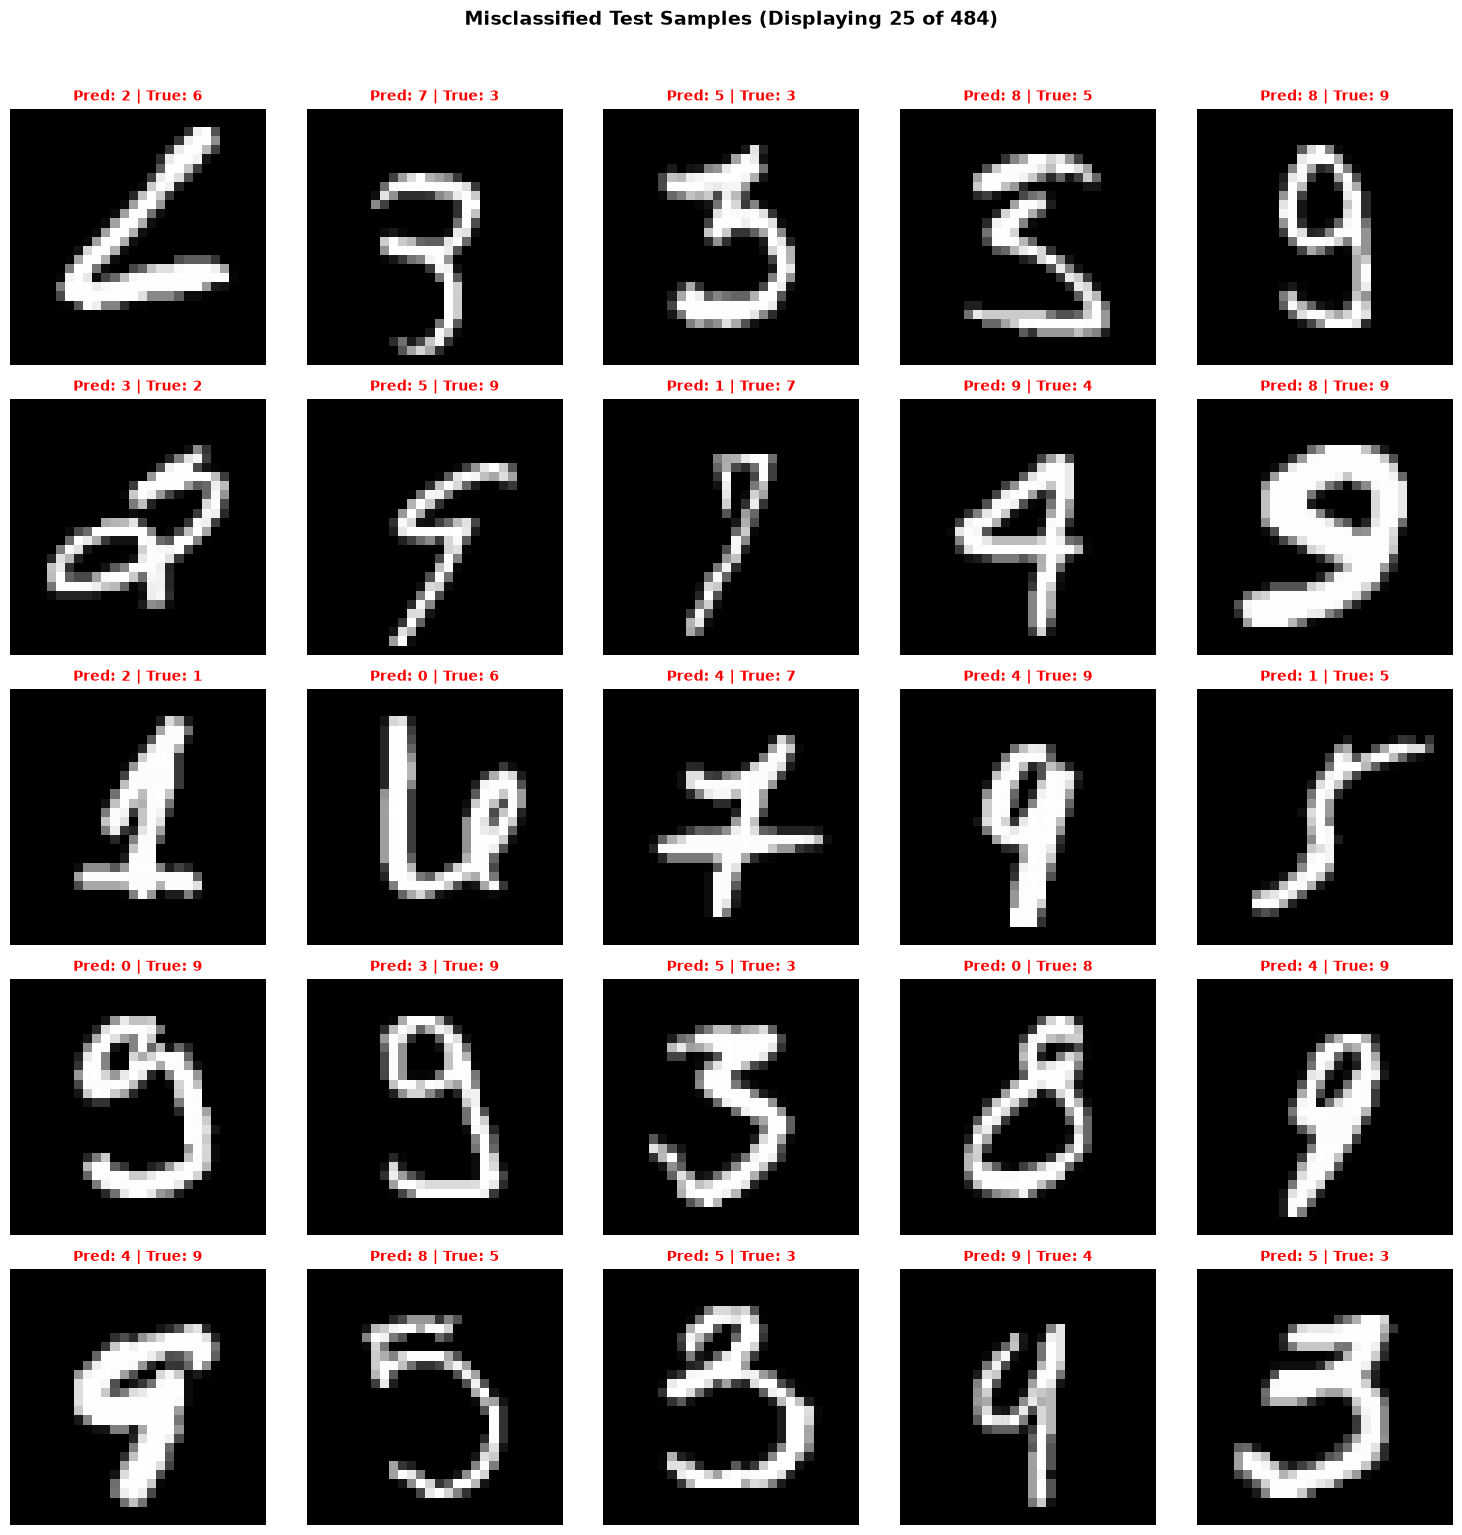

In [ ]:
def plot_error_samples(test_x, error_indices, num_samples=25, cols=5, randomize=True):
    display_count = min(num_samples, len(error_indices))
    rows = math.ceil(display_count / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    
    if display_count == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    # sample indices (random subset / first N errors)
    if randomize and len(error_indices) > display_count:
        sampled_records = [error_indices[i] for i in np.random.choice(len(error_indices), size=display_count, replace=False)]
    else:
        sampled_records = error_indices[:display_count]

    # images with red title highlighting misclassifications
    for i, (orig_idx, true_label, pred_label) in enumerate(sampled_records):
        image = test_x[orig_idx]
        axes[i].imshow(image.reshape(28, 28), cmap='gray')
        axes[i].set_title(f"Pred: {pred_label} | True: {true_label}", color='red', fontsize=10, fontweight='bold')
        axes[i].axis('off')

    for j in range(display_count, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f"Misclassified Test Samples (Displaying {display_count} of {len(error_indices)})", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

plot_error_samples(test_x, error_indices)

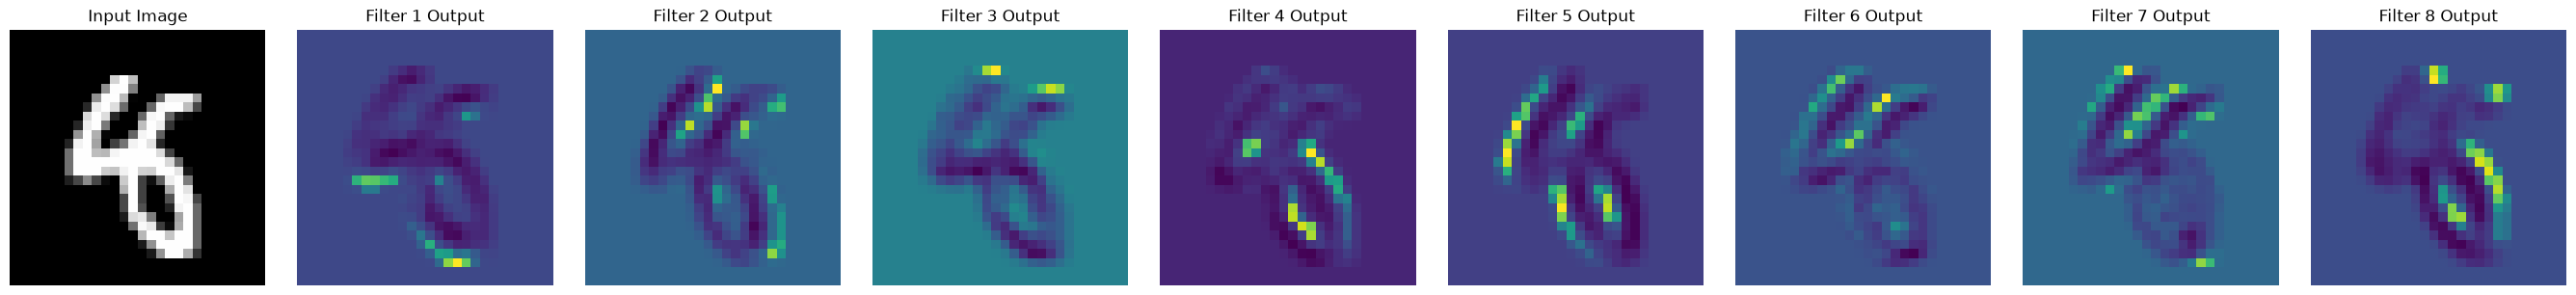

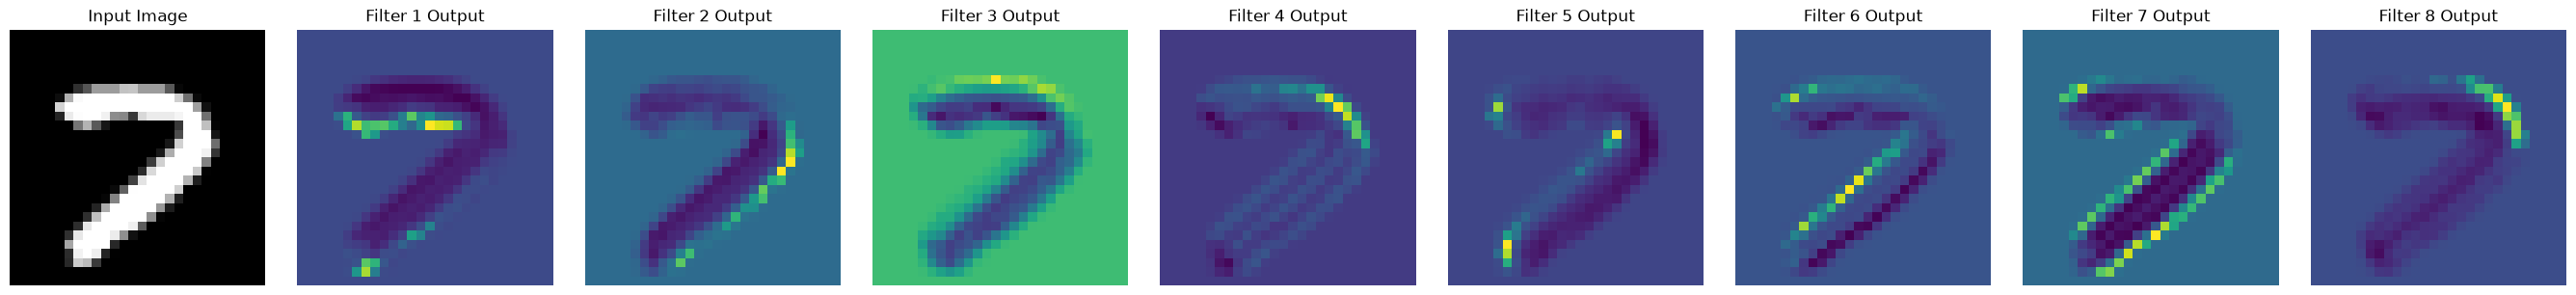

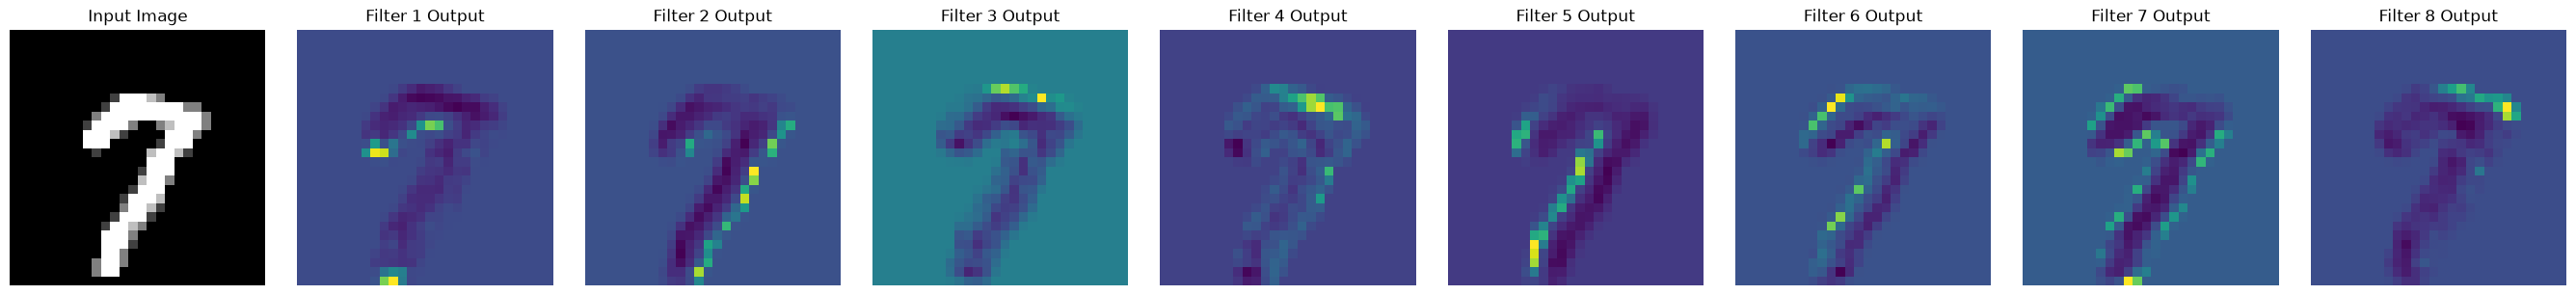

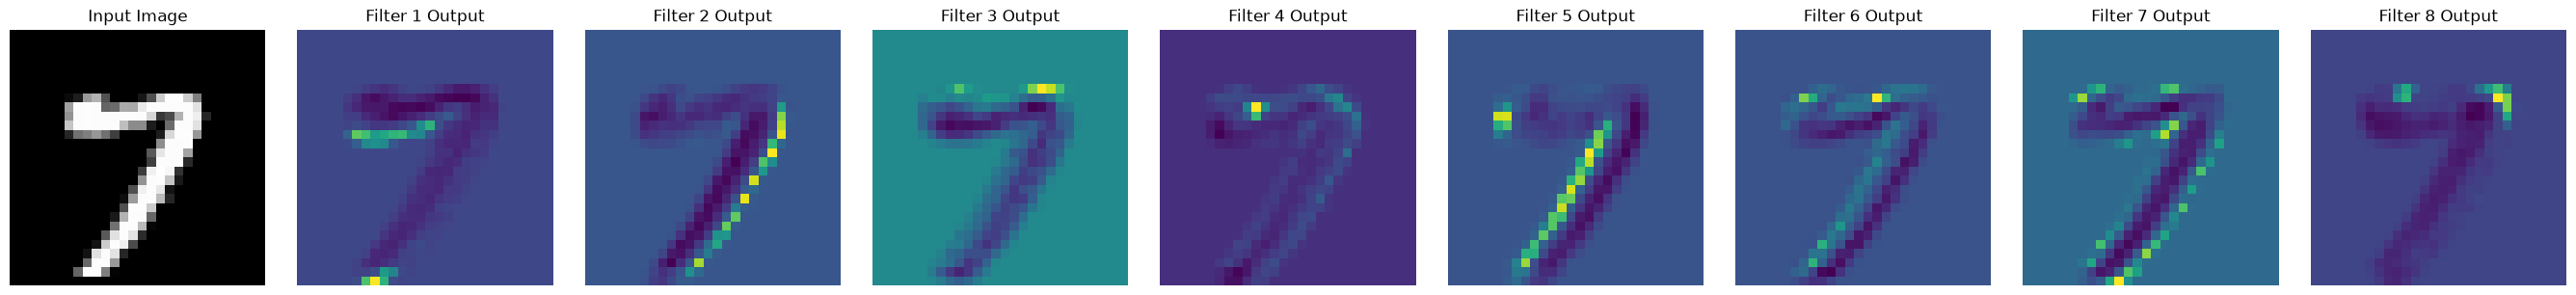

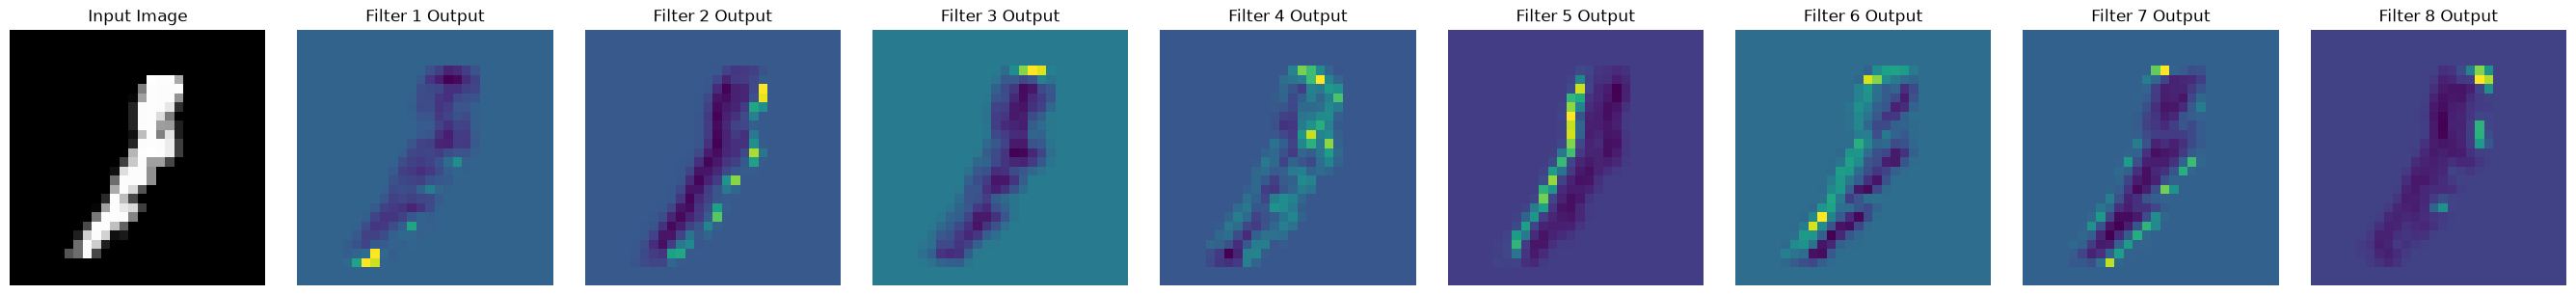

In [ ]:
def visualize_conv_features(sample_image, conv_layer):
    x = sample_image.reshape(1, 28, 28)
    acts = conv_layer.forward(x)  

    num_filters = acts.shape[0]
    fig, axes = plt.subplots(1, num_filters + 1, figsize=(3 * (num_filters + 1), 3))

    axes[0].imshow(sample_image.reshape(28, 28), cmap='gray')
    axes[0].set_title("Input Image")
    axes[0].axis('off')

    for idx in range(num_filters):
        axes[idx + 1].imshow(acts[idx], cmap='viridis')
        axes[idx + 1].set_title(f"Filter {idx+1} Output")
        axes[idx + 1].axis('off')

    plt.tight_layout()
    plt.show()

num_samples = 5
random_indices = np.random.choice(len(test_x), size=min(num_samples, len(test_x)), replace=False)
for i in random_indices:
    visualize_conv_features(test_x[i], model.conv1)